# Frozen Bridge retrieval geometry and reference-only whitening

This report asks whether frozen BridgeRNA embeddings preserve cross-pipeline sample identity, why ordinary cosine similarity is unusually high, and whether an ARCHS4-fitted geometry correction improves both technical-identity and tissue retrieval.

Bridge is not trained or fine-tuned in this analysis. Every result below is loaded from validated compact cached tables.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / 'data').exists():
    candidates = [p for p in ROOT.rglob('sample_retrieval_geometry') if (p / 'data').exists()]
    if not candidates:
        raise FileNotFoundError('Run from notebooks/sample_retrieval_geometry or the repository root')
    ROOT = candidates[0]

provenance = json.loads((ROOT / 'provenance.json').read_text())
assert provenance['verification']['status'] == 'passed'
print(f"Validated cached package: {ROOT}")


Validated cached package: /home/walt/bridge-rna.worktrees/we-are-creating-a-new-bridge-benchmark-to/notebooks/sample_retrieval_geometry


## Cohorts and frozen protocol

- **Technical identity:** 562 exact ARCHS4↔recount3 GSM pairs from 40 repository-defined unseen studies, searched against 510,709 human ARCHS4 references.
- **Embedding geometry:** 2,000,000 deterministic distinct random ARCHS4 pairs (seed 20260922).
- **Biological retrieval:** 6,064 eligible GTEx v11 queries across 13 harmonized tissues, searched against 510,376 ARCHS4 references after 333 explicit GTEx-origin exclusions.
- **Different-donor control:** each GTEx query excludes itself and every sample from the same donor.

BridgeRNA is frozen. The post-processing transform is fitted only on the ARCHS4 reference corpus: full 512-dimensional covariance whitening with denominator *N*, eigenvalue floor $\lambda_{max}	imes10^{-12}$, L2 normalization, and cosine ranking. The transform is applied unchanged to recount3 and GTEx queries.


## 1. Absolute agreement is distinct from retrieval uniqueness

In [2]:
pair = pd.read_csv(ROOT / 'data/exact_pair_similarity_summary.csv')
random_exact = pd.read_csv(ROOT / 'data/random_vs_exact_similarity.csv')
poor_rank = pd.read_csv(ROOT / 'data/high_similarity_poor_rank.csv')
display(pair.round(6))
display(random_exact[['distribution','n','mean','median','sd','q1','q3','minimum','maximum']].round(6))
display(poor_rank.round(6))


,samples,studies,sample_level_mean_cosine,sample_level_median_cosine,study_macro_mean_cosine,study_macro_median_cosine,median_across_study_means,median_across_study_medians,sd_across_study_means,minimum_study_mean,maximum_study_mean
0,562,40,0.997806,0.999218,0.996569,0.99674,0.998803,0.998942,0.004667,0.977107,0.999689


,distribution,n,mean,median,sd,q1,q3,minimum,maximum
0,Random ARCHS4 pairs,2000000,0.878748,0.912954,0.118144,0.862537,0.941537,-0.443058,0.999929
1,Exact ARCHS4-recount3 pairs,562,0.997806,0.999218,0.003510,0.998496,0.999460,0.974058,0.999822


,rank_threshold,cosine_threshold,queries,fraction_all_queries,fraction_among_poor_rank
0,100,0.99,33,0.058719,0.717391
1,1000,0.99,7,0.012456,0.500000


Across 562 exact pairs, mean cosine is **0.997806** and median cosine is **0.999218**, versus a sampled random-pair median of **0.912954**. Yet 33 queries have rank >100 while retaining exact-pair cosine >0.99. High absolute agreement therefore does not imply a unique nearest neighbor in a crowded reference corpus.


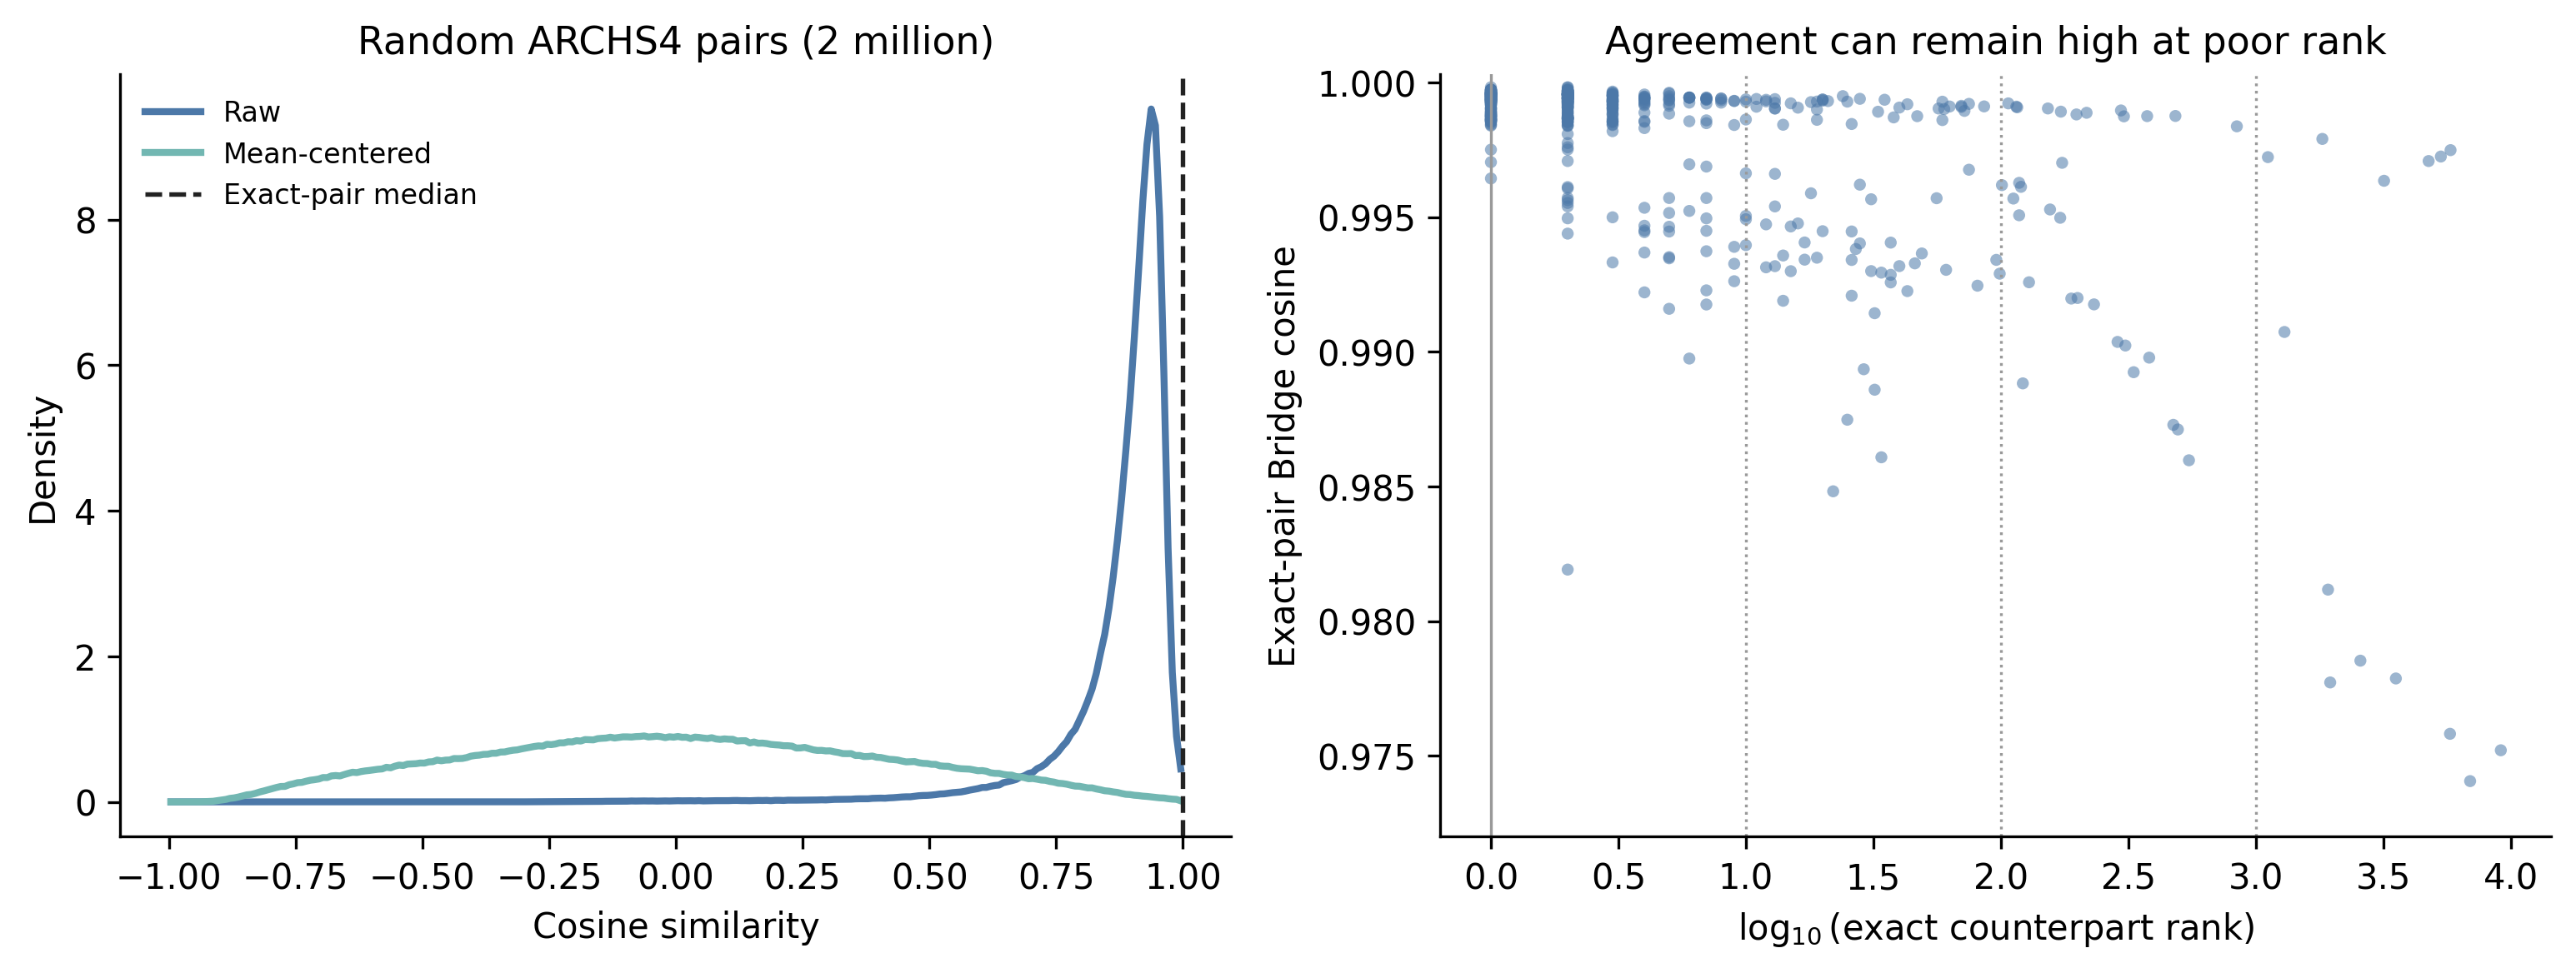

In [3]:
display(Image(filename=str(ROOT / 'figures/figure_1_geometry_and_uniqueness.png')))

## 2. A shared global direction explains the high raw cosine baseline

Mean random-pair cosine is 0.878748, almost identical to the squared magnitude of the unit directional mean (0.878774). Mean-centering moves the random-pair median from 0.912954 to −0.002471. This quantitative match identifies strong anisotropy—not failed sample discrimination—as the main reason ordinary Bridge cosine is high.


In [4]:
anis = pd.read_csv(ROOT / 'data/anisotropy_summary.csv')
geom = pd.read_csv(ROOT / 'data/geometry_distribution_summary.csv')
display(anis[['references','embedding_dim','unit_directional_mean_norm_squared','participation_ratio']].round(6))
display(geom[['representation','n','mean','median','sd','p5','p95','minimum','maximum']].round(6))


,references,embedding_dim,unit_directional_mean_norm_squared,participation_ratio
0,510709,512,0.878774,2.907422


,representation,n,mean,median,sd,p5,p95,minimum,maximum
0,Raw,2000000,0.878748,0.912954,0.118144,0.673433,0.967828,-0.443058,0.999929
1,Mean-centered,2000000,0.006452,-0.002471,0.406919,-0.655725,0.692437,-0.948116,0.999563


## 3. Reference-only whitening improves exact cross-pipeline retrieval

In [5]:
micro = pd.read_csv(ROOT / 'data/exact_retrieval_micro.csv')
macro = pd.read_csv(ROOT / 'data/exact_retrieval_study_macro.csv')
display(micro[['method','r_at_1','r_at_5','r_at_10','r_at_100','r_at_1000','mrr','median_rank']].round(4))
display(macro[['method','studies','macro_r_at_1','macro_r_at_5','macro_r_at_10','macro_r_at_100','macro_r_at_1000','macro_mrr']].round(4))


,method,r_at_1,r_at_5,r_at_10,r_at_100,r_at_1000,mrr,median_rank
0,Raw cosine,0.2847,0.6957,0.7722,0.9181,0.9751,0.4764,2.0
1,Whitening,0.4662,0.9342,0.9448,0.9911,1.0000,0.6919,2.0


,method,studies,macro_r_at_1,macro_r_at_5,macro_r_at_10,macro_r_at_100,macro_r_at_1000,macro_mrr
0,Raw cosine,40.0,0.3297,0.6597,0.7592,0.9133,0.9698,0.4886
1,Whitening,40.0,0.3766,0.9243,0.9412,0.9792,1.0000,0.6457


Whitening raises sample-micro R@1 from **28.47% to 46.62%**, R@10 from **77.22% to 94.48%**, R@100 from **91.81% to 99.11%**, and MRR from **0.4764 to 0.6919**. Equal-weight study-macro R@10 rises from **75.92% to 94.12%**. Random chance is $K/510{,}709$ for R@K, so even the raw result is far above chance; whitening makes the exact counterpart substantially more unique.


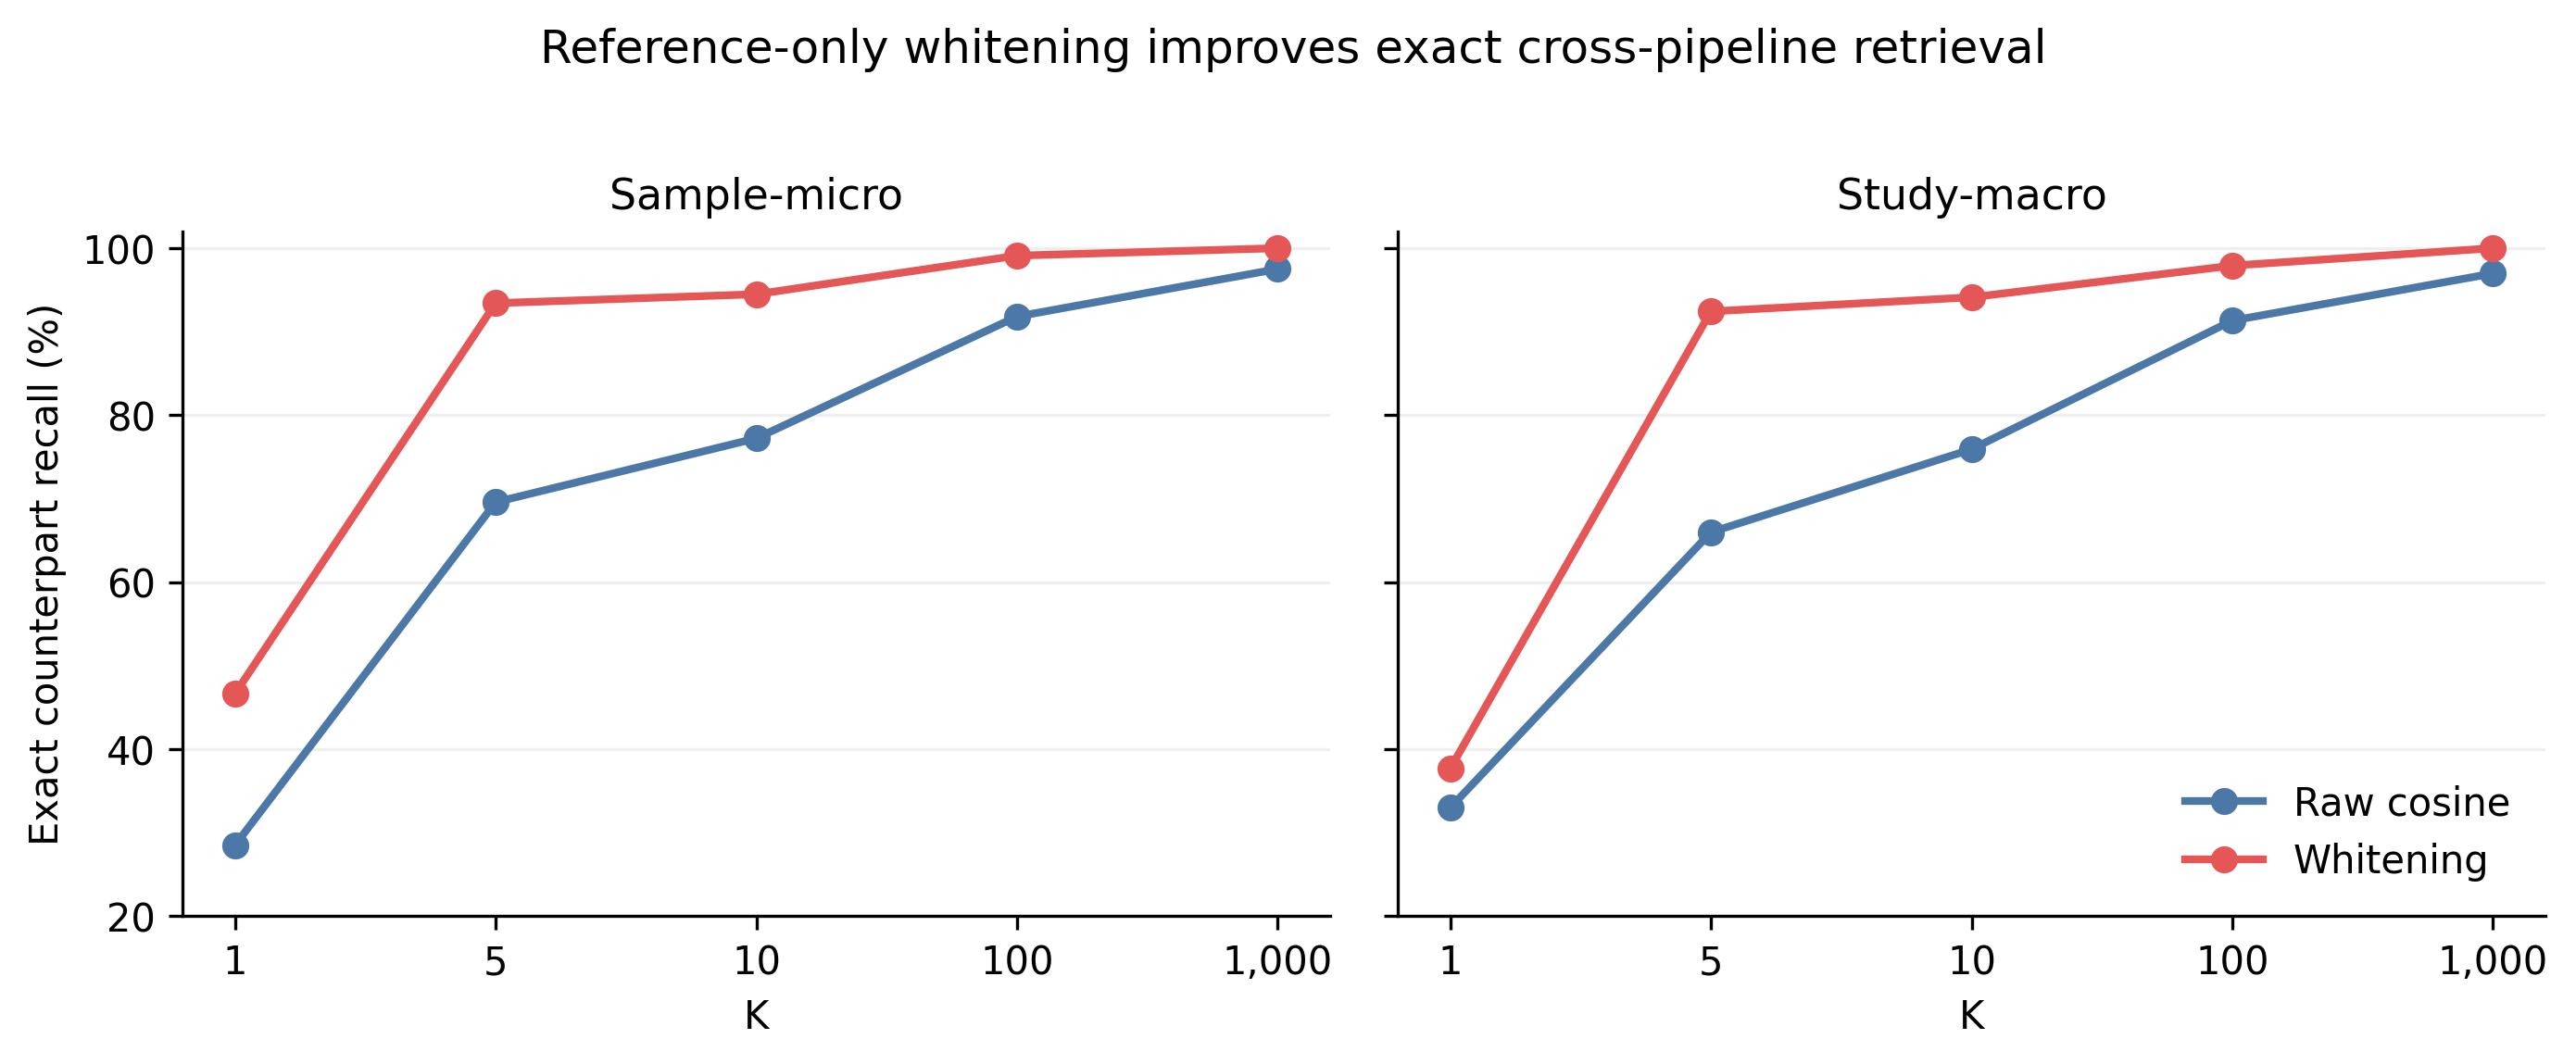

In [6]:
display(Image(filename=str(ROOT / 'figures/figure_2_exact_retrieval.png')))

## 4. The gain extends to tissue organization

In [7]:
gtex_macro = pd.read_csv(ROOT / 'data/gtex_archs4_tissue_macro.csv')
gtex_control = pd.read_csv(ROOT / 'data/gtex_gtex_donor_excluded.csv')
display(gtex_macro[gtex_macro.k == 10][['method','tissues','annotated_precision','absolute_hit_rate','unknown_rate','fold_enrichment']].round(4))
display(gtex_control[gtex_control.k == 10][['method','queries','micro_precision','tissue_macro_precision','tissues']].round(4))


,method,tissues,annotated_precision,absolute_hit_rate,unknown_rate,fold_enrichment
2,Raw cosine,13,0.8673,0.2313,0.7551,136.6045
6,Whitening,13,0.9121,0.2477,0.7361,147.4147


,method,queries,micro_precision,tissue_macro_precision,tissues
2,Raw cosine,6064,0.9228,0.9061,16
6,Whitening,6064,0.9565,0.9486,16


In GTEx→ARCHS4 retrieval, tissue-macro annotated P@10 increases from **86.73% to 91.21%** and absolute Hit@10 from **23.13% to 24.77%**. Approximately **74%** of Top-10 references are unlabeled under the deliberately conservative ARCHS4 mapping, so annotated precision must be read alongside Hit@10 and Unknown@10.

The fully labeled different-donor GTEx→GTEx control provides the cleaner biological validation: whitening raises tissue-macro P@10 from **90.61% to 94.86%** and micro P@10 from **92.28% to 95.65%**.


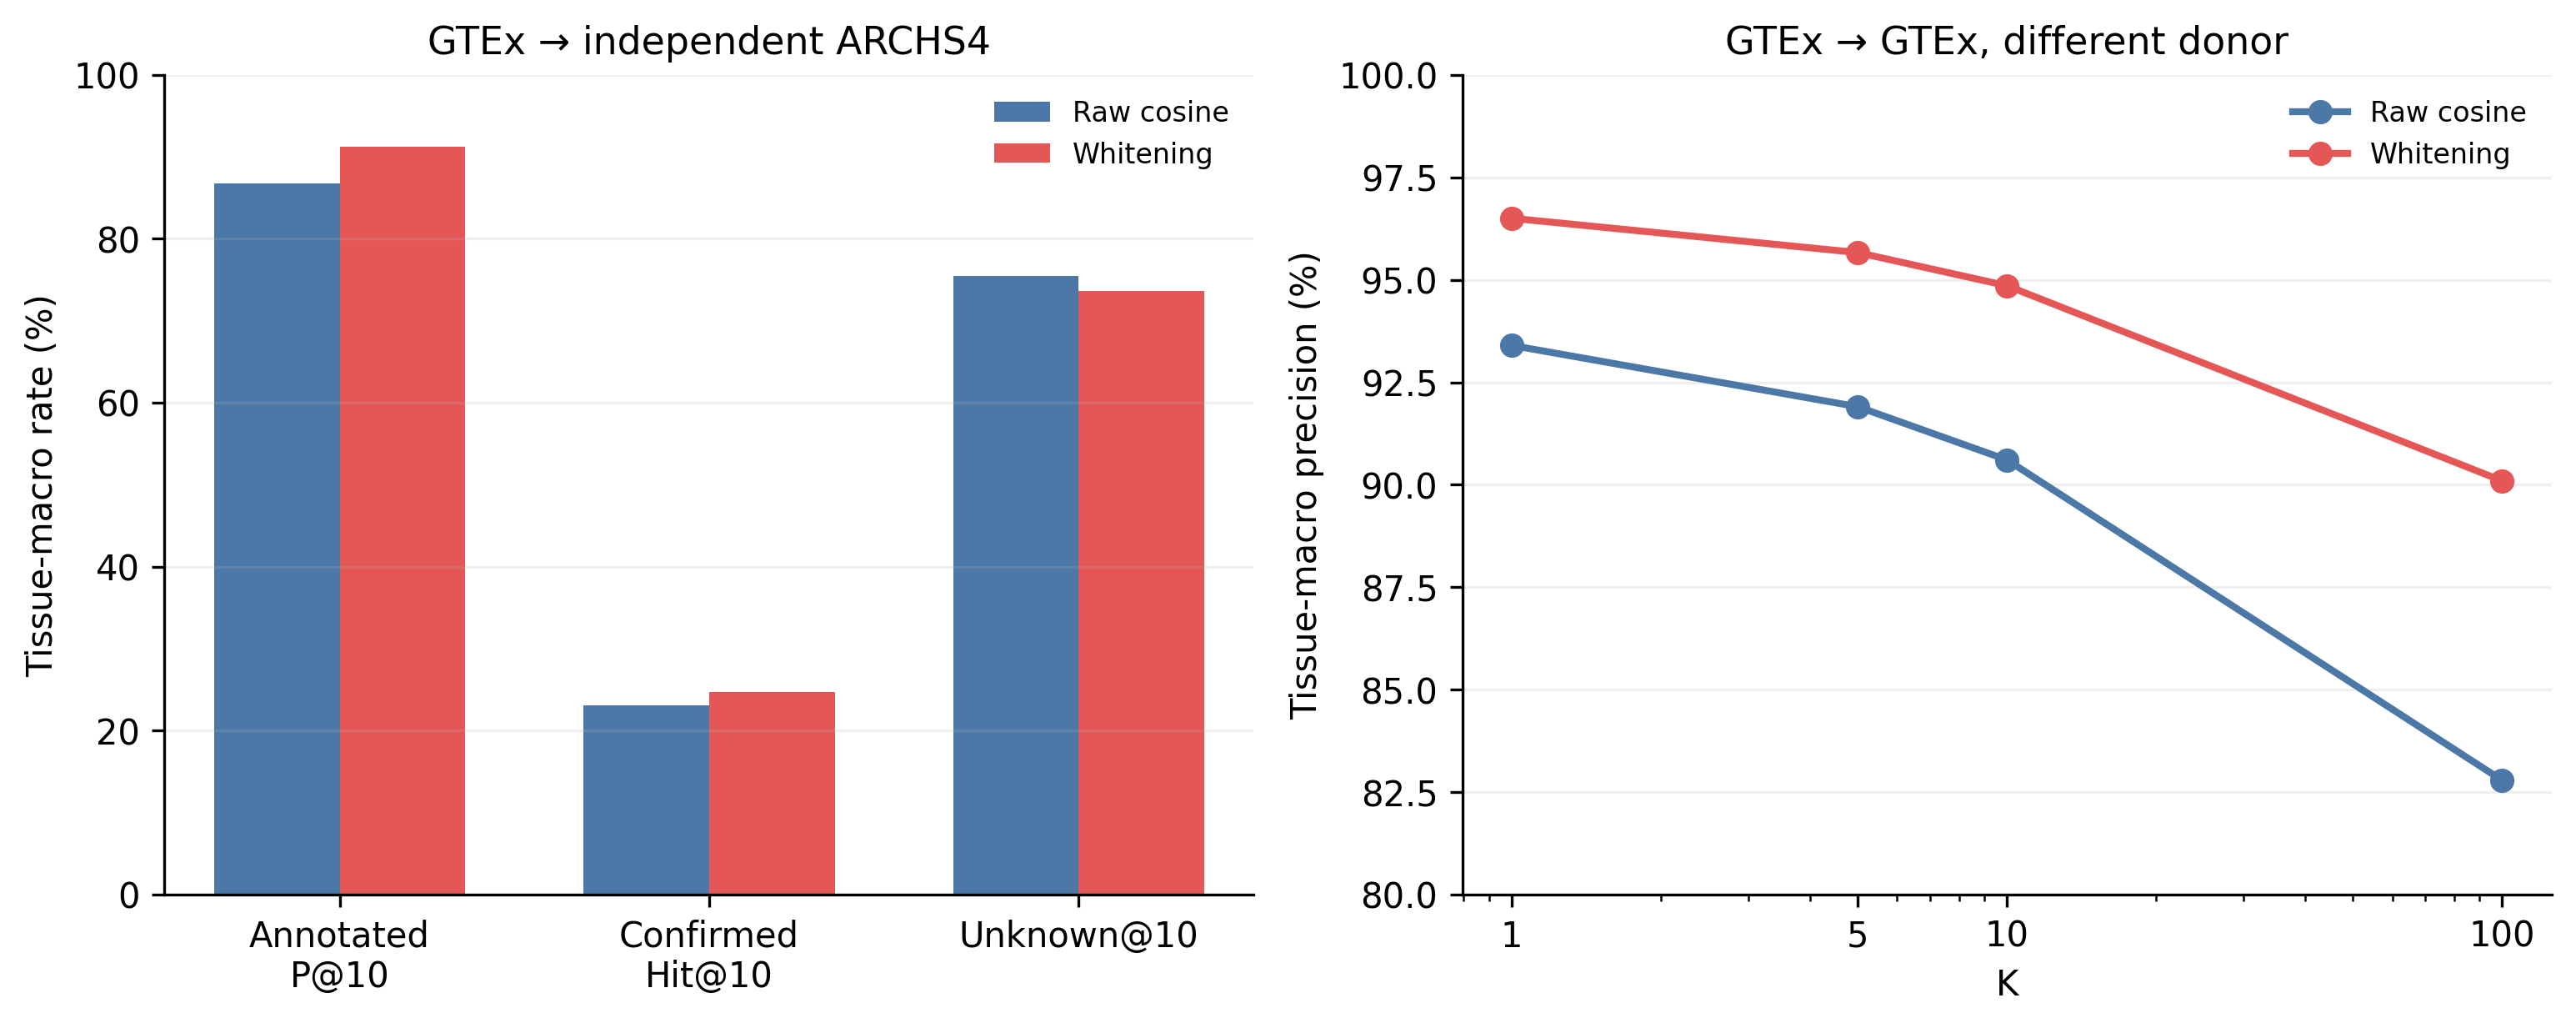

In [8]:
display(Image(filename=str(ROOT / 'figures/figure_3_biological_retrieval.png')))

## Limitations

- The ARCHS4 pairwise distribution is a deterministic sample, not an exhaustive evaluation of roughly 130 billion unique pairs.
- Exact ARCHS4↔recount3 matches are cross-pipeline technical counterparts, not independent biological replicates.
- Conservative ARCHS4 tissue annotation is sparse. Unknowns are retained explicitly; the GTEx→ARCHS4 claim is therefore conditional on annotated neighbors.
- The different-donor GTEx→GTEx experiment is a standardized-dataset control, not independent-study validation.
- Whitening is post hoc geometry correction. It is not training and is not evidence that BridgeRNA is batch-corrected.

## Conclusion

Frozen BridgeRNA strongly preserves cross-pipeline sample identity, but raw cosine is dominated by a shared global direction and can obscure retrieval uniqueness. A full whitening transform fitted only on ARCHS4 references markedly improves exact retrieval and also improves tissue organization in both independent ARCHS4 search and a fully labeled different-donor GTEx control. Raw cosine remains the interpretable measure of absolute representation agreement; reference-only whitening is the supported ranking geometry.
